# 08 — Expanded HRI: provisional weights and sensitivity

User-authorized exploratory expansion of the forest HRI. This notebook includes every available environmental/context variable in an audited table, gives explicitly provisional weights to supported pressure proxies, and compares alternative priorities. It does not replace the released core HRI or the completed forecast experiment.

**Exact weights are analyst assumptions, not learned ecological importance.** Climate departure is an exposure hypothesis; terrain requires a species-specific response; sampled NDVI/land cover cannot stand in for national annual raster measurements. The point-greenness score is a separate sensitivity illustration and is excluded from forecasting targets.

Run cells in order. All processing code is visible. Outputs go only to `data/processed/hri/expanded_provisional_v1/`.

## 1 — Inputs, configuration and all-variable audit table

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

ROOT = globals().get('ROOT')
if ROOT is None:
    ROOT = next((p for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                 for p in [base, base/'components/habitat_risk'] if (p/'configs/hri.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open Jupyter inside the repository.')
CONFIG_PATH = ROOT/'configs/hri_expanded_provisional.json'
CONFIG = json.loads(CONFIG_PATH.read_text())
OUT = ROOT/'data/processed/hri/expanded_provisional_v1'
KEY = ['cell_id','reference_year']
CORE = ['forest_amount_risk','recent_loss_risk','cumulative_loss_risk','fragmentation_risk']

def digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def class_labels(values):
    return pd.cut(values, [-np.inf,100/3,200/3,np.inf], labels=['Low','Moderate','High']).astype('string')

def validate_weights(weights):
    values = np.asarray(list(weights.values()),dtype=float)
    if not len(values) or not np.isfinite(values).all() or (values<0).any() or not np.isclose(values.sum(),1):
        raise ValueError('Weights must be finite, nonnegative, and sum to one.')

def flatten_weights(domain_weights, within=None):
    within = CONFIG['within_domain_weights'] if within is None else within
    validate_weights(domain_weights)
    result = {}
    for domain, domain_weight in domain_weights.items():
        validate_weights(within[domain])
        for component, fraction in within[domain].items():
            if domain_weight > 0 and fraction > 0:
                result[component] = float(domain_weight*fraction)
    validate_weights(result)
    return result

def weighted_index(frame, weights, eligibility):
    validate_weights(weights)
    fields = [k for k,v in weights.items() if v>0]
    used = frame[fields].replace([np.inf,-np.inf],np.nan)
    if ((used<0)|(used>1)).any().any():
        raise ValueError('Risk components must be within [0,1].')
    available_weight = used.notna().mul(pd.Series(weights)).sum(axis=1)
    complete = used.notna().all(axis=1) & eligibility
    score = used.mul(pd.Series(weights)).sum(axis=1)*100
    return score.where(complete), available_weight

def frozen_scale(values, reference_mask, absolute=False, logarithmic=False):
    numeric = pd.to_numeric(values,errors='coerce').replace([np.inf,-np.inf],np.nan)
    numeric = numeric.abs() if absolute else numeric.where(numeric.ge(0))
    transformed = np.log1p(numeric) if logarithmic else numeric
    upper = float(transformed.loc[reference_mask].quantile(CONFIG['normalization_quantile']))
    if not np.isfinite(upper) or upper<=0:
        raise ValueError('No positive calibration scale.')
    return (transformed/upper).clip(0,1), upper

def load_all_variables():
    master_path = ROOT/'data/processed/hri/pre_hri_v1/master_cell_year_dataset.csv'
    core_path = ROOT/'data/processed/hri/hri_v1/hri_core_equal_complete_cases.csv'
    context_path = ROOT/'data/processed/hri/model_v1/final_hri_model_dataset.csv'
    master = pd.read_csv(master_path,low_memory=False)
    core = pd.read_csv(core_path,usecols=KEY+CORE+['hri_score_0_100'])
    context = pd.read_csv(context_path,low_memory=False)
    context = context[KEY+[c for c in context if c.startswith('context__')]]
    for table in [master,core,context]:
        if table.duplicated(KEY).any():
            raise ValueError('Duplicate cell/year input.')
    # Use physical master values, not the already-imputed legacy model predictors.
    frame = master.merge(core,on=KEY,how='left',validate='one_to_one')
    frame = frame.merge(context,on=KEY,how='left',validate='one_to_one')
    return frame, {'master':master_path,'core':core_path,'context':context_path}


## 2 — Derive pressure proxies with frozen 2010–2014 scales

In [2]:
def prepare_components(frame):
    d = frame.copy()
    core_eligible = d[CORE].notna().all(axis=1)
    reference = d.reference_year.isin(CONFIG['reference_years']) & core_eligible
    scales = {}
    # Raw temperature/rainfall feed departures; they do not get a second independent weight.
    for variable,prefix in [('climate__annual_mean_temperature_c','temperature'),
                            ('climate__annual_precipitation_mm','precipitation')]:
        baselines = d.loc[d.reference_year.isin(CONFIG['reference_years'])].groupby('cell_id')[variable].agg(['mean','count'])
        valid = baselines['count'].ge(CONFIG['minimum_climate_reference_years_per_cell'])
        baseline = baselines['mean'].where(valid)
        reference_mean = d.cell_id.map(baseline)
        d[prefix+'_reference_mean_2010_2014'] = reference_mean
        departure = d[variable] - reference_mean
        d[prefix+'_departure_from_reference'] = departure
        d[prefix+'_departure_risk'],scales[prefix+'_absolute_departure_P99'] = frozen_scale(departure,reference,absolute=True)
    for variable,prefix in [('climate__temperature_c_trailing5_slope_per_year','temperature'),
                            ('climate__precipitation_mm_trailing5_slope_per_year','precipitation')]:
        d[prefix+'_trend_magnitude_risk'],scales[prefix+'_absolute_trend_P99'] = frozen_scale(d[variable],reference,absolute=True)
    population = d['pressure__population_density_per_km2'].where(d['pressure__population_density_per_km2'].ge(0))
    population = population.where(d['pressure__population_source_year'].le(d.reference_year))
    d['population_pressure_risk'],scales['log_population_P99'] = frozen_scale(population,reference,logarithmic=True)
    # Point NDVI is a sparse greenness illustration, not a harmonized vegetation degradation measure.
    ndvi = pd.to_numeric(d['context__sampled_ndvi_mean'],errors='coerce')
    d['sampled_greenness_deficit'] = (1-ndvi).where(ndvi.between(0,1))
    d['core_eligible'] = core_eligible
    d['assessment_eligible'] = core_eligible & d.reference_year.ge(CONFIG['first_assessment_year'])
    d['expanded_provisional_score'],d['expanded_available_nominal_weight'] = weighted_index(d,flatten_weights(CONFIG['domain_weights']),d.assessment_eligible)
    d['expanded_provisional_class'] = class_labels(d.expanded_provisional_score)
    d['expanded_status'] = np.select([~core_eligible,d.reference_year.lt(CONFIG['first_assessment_year']),d.expanded_provisional_score.isna()],
        ['outside_core_eligibility','calibration_period_only','missing_positive_weight_component'],default='eligible_provisional')
    d['forest_climate_only_score'],_ = weighted_index(d,flatten_weights(CONFIG['forest_climate_only_weights']),d.assessment_eligible)
    sampled = CONFIG['sampled_vegetation_sensitivity']
    # This scenario has 90% domain contributions plus 10% sampled vegetation.
    sample_weights = {component:0.0 for component in flatten_weights(CONFIG['domain_weights'])}
    for domain,weight in sampled['domain_weights'].items():
        for component,fraction in CONFIG['within_domain_weights'][domain].items():
            sample_weights[component] = weight*fraction
    sample_weights['sampled_greenness_deficit'] = sampled['sampled_greenness_deficit_weight']
    validate_weights(sample_weights)
    d['sampled_greenness_sensitivity_score'],_ = weighted_index(d,sample_weights,d.assessment_eligible)
    if not sampled['enabled']:
        d['sampled_greenness_sensitivity_score'] = np.nan
    # Exact next-year score labels, never an imputed substitute for a missing future score.
    future = d[KEY+['expanded_provisional_score']].copy()
    future.reference_year -= 1
    future = future.rename(columns={'expanded_provisional_score':'expanded_provisional_score_t1'})
    d = d.merge(future,on=KEY,how='left',validate='one_to_one')
    d['expanded_provisional_target_year_t1'] = d.reference_year+1
    return d,scales,sample_weights


## 3 — Compare weight scenarios on identical rows

In [3]:
def sensitivity(d):
    primary = flatten_weights(CONFIG['domain_weights'])
    scenarios = {'provisional_primary':CONFIG['domain_weights'],**CONFIG['domain_sensitivity_scenarios']}
    common = d.loc[d.expanded_provisional_score.notna()].copy()
    if len(common)<2:
        raise ValueError('Insufficient complete cases for matched sensitivity.')
    rows,weights_rows = [],[]
    original = common.expanded_provisional_score
    top_n = max(1,int(np.ceil(len(common)*.1)))
    original_top = set(original.nlargest(top_n).index)
    for name,domain_weights in scenarios.items():
        weights = flatten_weights(domain_weights)
        alternative,_ = weighted_index(common,weights,pd.Series(True,index=common.index))
        alternative_top = set(alternative.nlargest(top_n).index)
        rows.append({'scenario':name,'n_matched_rows':len(common),
            'spearman_rank_correlation':original.corr(alternative,method='spearman'),
            'mean_absolute_score_change':float((alternative-original).abs().mean()),
            'class_changed_fraction':float(class_labels(original).ne(class_labels(alternative)).mean()),
            'top_decile_jaccard':len(original_top&alternative_top)/len(original_top|alternative_top)})
        for component,weight in weights.items():
            weights_rows.append({'scenario':name,'component':component,'weight':weight,'status':'provisional_analyst_assumption'})
    # Hierarchical perturbations explore both domain and within-domain uncertainty.
    rng = np.random.default_rng(CONFIG['random_seed'])
    domains = list(CONFIG['domain_weights'])
    components = list(primary)
    simulations = []
    perturbations = []
    for draw in range(CONFIG['weight_perturbation_draws']):
        domain_draw = rng.dirichlet(np.array([CONFIG['domain_weights'][k] for k in domains])*CONFIG['dirichlet_concentration_domains'])
        weights = {}
        for domain,domain_weight in zip(domains,domain_draw):
            inside = CONFIG['within_domain_weights'][domain]
            fractions = rng.dirichlet(np.array(list(inside.values()))*CONFIG['dirichlet_concentration_within_domains'])
            weights.update({k:float(domain_weight*v) for k,v in zip(inside,fractions)})
        validate_weights(weights)
        values = common[components].mul(pd.Series(weights)).sum(axis=1)*100
        simulations.append(values.to_numpy())
        perturbations.append({'draw':draw,**weights,'rank_correlation':original.corr(values,method='spearman')})
    matrix = np.array(simulations)
    intervals = common[KEY+['expanded_provisional_score']].copy()
    intervals['weight_sensitivity_P05'] = np.quantile(matrix,.05,axis=0)
    intervals['weight_sensitivity_P95'] = np.quantile(matrix,.95,axis=0)
    intervals['interpretation'] = 'weight-choice scenario envelope, not a statistical confidence interval'
    return pd.DataFrame(rows),pd.DataFrame(weights_rows),pd.DataFrame(perturbations),intervals,common[components].corr(method='spearman')

def variable_register(d):
    weights = flatten_weights(CONFIG['domain_weights'])
    rows=[]
    for column in d.columns:
        if column in KEY:
            continue
        role = 'audit_or_derived_output'
        reason = 'Stored for audit; not an independently weighted pressure.'
        if column in weights:
            role='provisional_pressure_component'
            reason='Explicit normalized indicator in the grouped provisional index.'
        elif column.startswith('terrain__') or column=='context__sampled_elevation_mean_m':
            role='terrain_context'
            reason='No universal adverse direction; requires species tolerance or ecological response model.'
        elif 'land_cover' in column:
            role='unverified_sampled_land_cover_context'
            reason='Product-specific categories; historical product/QA and risk-response mapping not verified.'
        elif 'ndvi' in column or column=='sampled_greenness_deficit':
            role='sparse_sampled_vegetation_context'
            reason='Point-sampled, sensor/date/season/QA unverified; only a separately labelled sensitivity illustration.'
        elif column.startswith('climate__'):
            role='climate_source_or_context'
            reason='Raw mean inputs form departure indicators. Avoid independently weighting duplicate raw and derived quantities.'
        elif column.startswith('pressure__'):
            role='population_source_or_coverage'
            reason='Population density feeds one pressure proxy; counts/coverage are not extra pressures.'
        elif column.startswith('context__'):
            role='observation_or_sampling_context'
            reason='Sampling effort/coverage is not ecological degradation.'
        rows.append({'column':column,'role':role,'available_rows':int(d[column].notna().sum()),
                     'total_rows':len(d),'primary_nominal_weight':weights.get(column,0.),'reason':reason})
    return pd.DataFrame(rows)


## 4 — Execute derivation and show coverage

In [4]:
raw,sources = load_all_variables()
expanded,scale_parameters,sampled_weights = prepare_components(raw)
comparisons,scenario_weights,perturbations,envelopes,correlations = sensitivity(expanded)
register = variable_register(expanded)
display(scenario_weights.loc[scenario_weights.scenario.eq('provisional_primary')])
coverage = expanded.groupby('reference_year').agg(
    rows=('cell_id','size'), core_scores=('hri_score_0_100','count'),
    expanded_scores=('expanded_provisional_score','count'),
    forest_climate_scores=('forest_climate_only_score','count'),
    sampled_greenness_scores=('sampled_greenness_sensitivity_score','count'))
display(coverage)
display(comparisons)
display(register.loc[register.role.ne('audit_or_derived_output')])
print('Final classes/weights need ecological review. Population after 2020 is not extrapolated.')


Final classes/weights need ecological review. Population after 2020 is not extrapolated.


,scenario,component,weight,status
0,provisional_primary,forest_amount_risk,0.200,provisional_analyst_assumption
1,provisional_primary,recent_loss_risk,0.150,provisional_analyst_assumption
2,provisional_primary,cumulative_loss_risk,0.100,provisional_analyst_assumption
3,provisional_primary,fragmentation_risk,0.150,provisional_analyst_assumption
4,provisional_primary,temperature_departure_risk,0.075,provisional_analyst_assumption
5,provisional_primary,precipitation_departure_risk,0.075,provisional_analyst_assumption
6,provisional_primary,temperature_trend_magnitude_risk,0.025,provisional_analyst_assumption
7,provisional_primary,precipitation_trend_magnitude_risk,0.025,provisional_analyst_assumption
8,provisional_primary,population_pressure_risk,0.200,provisional_analyst_assumption


,rows,core_scores,expanded_scores,forest_climate_scores,sampled_greenness_scores
reference_year,,,,,
2010,2869,2525,0,0,0
2011,2869,2525,0,0,0
2012,2869,2525,0,0,0
2013,2869,2525,0,0,0
2014,2869,2525,0,0,0
2015,2869,2525,2318,2342,117
2016,2869,2525,2318,2342,141
2017,2869,2525,2318,2342,159
2018,2869,2525,2318,2342,184


,scenario,n_matched_rows,spearman_rank_correlation,mean_absolute_score_change,class_changed_fraction,top_decile_jaccard
0,provisional_primary,13908,1.000000,2.538985e-15,0.000000,1.000000
1,balanced_domains,13908,0.876785,6.187819e+00,0.129422,0.370443
2,forest_emphasis,13908,0.964256,3.370301e+00,0.063345,0.666866
3,climate_emphasis,13908,0.927858,4.240384e+00,0.085778,0.573529
4,population_emphasis,13908,0.949389,3.496050e+00,0.044075,0.549861


,column,role,available_rows,total_rows,primary_nominal_weight,reason
0,climate__annual_mean_temperature_c,climate_source_or_context,35154,40166,0.000,Raw mean inputs form departure indicators. Avo...
1,climate__annual_mean_temperature_c_coverage,climate_source_or_context,40166,40166,0.000,Raw mean inputs form departure indicators. Avo...
2,climate__annual_precipitation_mm,climate_source_or_context,35154,40166,0.000,Raw mean inputs form departure indicators. Avo...
3,climate__annual_precipitation_mm_coverage,climate_source_or_context,40166,40166,0.000,Raw mean inputs form departure indicators. Avo...
4,climate__weather_status,climate_source_or_context,40166,40166,0.000,Raw mean inputs form departure indicators. Avo...
5,climate__temperature_c_anomaly,climate_source_or_context,22599,40166,0.000,Raw mean inputs form departure indicators. Avo...
6,climate__temperature_c_trailing5_slope_per_year,climate_source_or_context,25110,40166,0.000,Raw mean inputs form departure indicators. Avo...
7,climate__precipitation_mm_anomaly,climate_source_or_context,22599,40166,0.000,Raw mean inputs form departure indicators. Avo...
8,climate__precipitation_mm_trailing5_slope_per_...,climate_source_or_context,25110,40166,0.000,Raw mean inputs form departure indicators. Avo...
9,terrain__terrain_sampled_pixels,terrain_context,40166,40166,0.000,No universal adverse direction; requires speci...


## 5 — Export a separate provisional release and provenance

In [5]:
RUN_EXPORT = True
if RUN_EXPORT:
    OUT.mkdir(parents=True,exist_ok=True)
    expanded.to_csv(OUT/'all_available_variables_and_scores.csv',index=False)
    score_columns = KEY+['hri_score_0_100','expanded_provisional_score','expanded_provisional_class',
        'expanded_status','expanded_available_nominal_weight','forest_climate_only_score',
        'sampled_greenness_sensitivity_score','expanded_provisional_score_t1','expanded_provisional_target_year_t1']
    expanded[score_columns].to_csv(OUT/'provisional_scores.csv',index=False)
    register.to_csv(OUT/'variable_register.csv',index=False)
    coverage.to_csv(OUT/'coverage_by_year.csv')
    scenario_weights.to_csv(OUT/'scenario_weights.csv',index=False)
    comparisons.to_csv(OUT/'weight_sensitivity_comparison.csv',index=False)
    perturbations.to_csv(OUT/'weight_perturbations.csv',index=False)
    envelopes.to_csv(OUT/'weight_sensitivity_envelopes.csv',index=False)
    correlations.to_csv(OUT/'indicator_spearman_correlations.csv')
    counts = expanded['context__sampled_land_cover_mode'].value_counts(dropna=False).rename_axis('product_prefixed_category').reset_index(name='rows')
    counts['risk_mapping_status']='not_assigned_pending_product_and_ecological_verification'
    counts.to_csv(OUT/'sampled_land_cover_inventory.csv',index=False)
    audit={'version':CONFIG['version'],'status':CONFIG['status'],'rows':len(expanded),
           'expanded_score_rows':int(expanded.expanded_provisional_score.notna().sum()),
           'expanded_years':sorted(expanded.loc[expanded.expanded_provisional_score.notna(),'reference_year'].unique().tolist()),
           'normalization_reference_years':CONFIG['reference_years'],'scale_parameters':scale_parameters,
           'primary_domain_weights':CONFIG['domain_weights'],'primary_weights':flatten_weights(CONFIG['domain_weights']),
           'sampled_sensitivity_weights':sampled_weights,'config_sha256':digest(CONFIG_PATH),
           'input_sha256':{k:digest(v) for k,v in sources.items()},'missing_policy':CONFIG['missing_policy'],
           'context_only':CONFIG['context_only'],'unavailable_layers':CONFIG['unavailable_layers'],
           'sources':CONFIG['sources'],'source_limit':CONFIG['source_limit'],
           'existing_HRI_and_frozen_forecast_modified':False,'models_trained':False,
           'weight_envelope_interpretation':'sensitivity to analyst weight choices, not confidence intervals',
           'forecast_readiness':'Expanded pressure index ends with population availability in 2020. No valid 2022/2023 expanded labels exist. Do not reuse old core-HRI test results as validation of this new target.'}
    (OUT/'expanded_audit.json').write_text(json.dumps(audit,indent=2))
    print('Saved provisional outputs:',OUT)


Saved provisional outputs: /Users/keerthikeerthi/Desktop/J26-IT-359/components/habitat_risk/data/processed/hri/expanded_provisional_v1


## 6 — Plot matched weight sensitivity and data coverage

/Users/keerthikeerthi/.matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /var/folders/9t/169rn90s6v7d3q32wf3tsmrh0000gn/T/matplotlib-ckv7n67w because there was an issue with the default path (/Users/keerthikeerthi/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.
Matplotlib is building the font cache; this may take a moment.


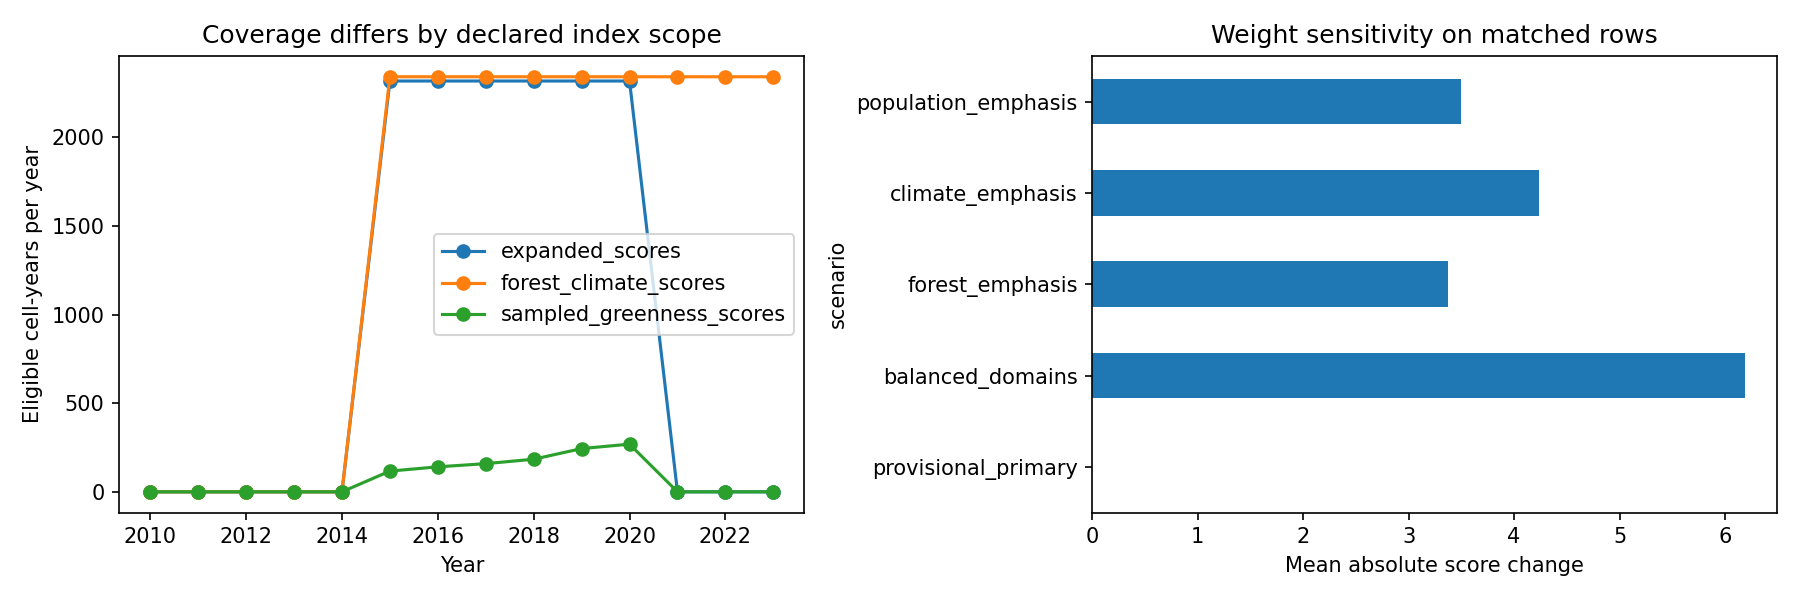

In [6]:
import matplotlib.pyplot as plt
from io import BytesIO
from IPython.display import Image
fig,axes=plt.subplots(1,2,figsize=(12,4))
coverage[['expanded_scores','forest_climate_scores','sampled_greenness_scores']].plot(ax=axes[0],marker='o')
axes[0].set(title='Coverage differs by declared index scope',ylabel='Eligible cell-years per year',xlabel='Year')
comparisons.set_index('scenario')['mean_absolute_score_change'].plot.barh(ax=axes[1])
axes[1].set(title='Weight sensitivity on matched rows',xlabel='Mean absolute score change')
fig.tight_layout()
buffer=BytesIO();fig.savefig(buffer,format='png',dpi=150)
display(Image(data=buffer.getvalue()))
if RUN_EXPORT:
    fig.savefig(OUT/'coverage_and_weight_sensitivity.png',dpi=180)
plt.close(fig)


## Interpretation and next decisions

The baseline forest share is 60%, climate departure 20%, and population pressure 20%. Within the forest domain, the absolute weights are 20% amount, 15% recent loss, 10% cumulative loss and 15% fragmentation. Climate has 7.5% each temperature/rainfall departure plus 2.5% each trend magnitude. Population contributes 20%. These are proposed priorities and require review.

All measured terrain, climate, sampled NDVI, land-cover categories, population, and observation-context fields are retained in the wide table. Retention is not the same as assigning every raw column an ecological penalty. Terrain needs species-specific response functions; land-cover codes need product and response validation. Coverage and effort flags must not masquerade as risk. Roads, built-up fractions and night lights are not currently measured in this dataset.

Sources support the methodology, not the exact numerical weights: [OECD/JRC composite indicator handbook](https://www.oecd.org/content/dam/oecd/en/publications/reports/2008/08/handbook-on-constructing-composite-indicators-methodology-and-user-guide_g1gh9301/9789264043466-en.pdf); [Foden et al. climate exposure/sensitivity framework](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0065427); [Venter et al. human footprint](https://www.nature.com/articles/ncomms12558); [MODIS vegetation-index measurement and QA](https://lpdaac.usgs.gov/documents/449/MOD13_ATBD_V5.pdf).

Use sensitivity comparisons and ecological expert feedback to choose a final indicator set and justify weights. This version must not replace the already-tested forecasting target or inherit its performance claims. Acquire later population coverage and accepted national vegetation/land-cover measurements before constructing a complete extended forecasting dataset.